## Dia 2 — Como os clientes avaliaram o atendimento?

### O problema

Uma equipe de atendimento recebeu 12 avaliações de clientes. A responsável pela equipe quer apresentar esses resultados em uma reunião e precisa responder a duas perguntas:

- Quantas avaliações foram ruins, regulares, boas ou ótimas?
- Qual porcentagem das respostas classificou o atendimento como bom ou ótimo?

Sua tarefa é organizar as respostas em uma tabela, construir um gráfico e escrever uma breve conclusão.

### Os dados

Use o arquivo `respostas.csv`, disponível na mesma pasta do notebook. Ele contém uma coluna chamada `resposta`, com uma avaliação por linha.

Organize as categorias nesta ordem:

**ruim → regular → boa → ótima**

O arquivo informa apenas as respostas recebidas. Ele não informa quantas pessoas foram convidadas a avaliar o atendimento. Portanto, use as **12 respostas como total** para calcular as proporções.

### O que fazer

**1. Conte as avaliações de cada categoria.**

Leia o arquivo e conte quantas vezes aparecem as respostas ruim, regular, boa e ótima. Essa contagem é a **frequência absoluta**.

**2. Organize uma tabela com as três frequências.**

A tabela deve ter uma linha por categoria, na ordem indicada, e estas colunas:

| Coluna | Como calcular |
| --- | --- |
| Frequência absoluta | Conte quantas respostas pertencem à categoria. |
| Frequência relativa | Divida a contagem da categoria pelo total de respostas. |
| Frequência relativa acumulada | Some as frequências relativas desde “ruim” até a categoria daquela linha. |

Calcule as frequências relativas como proporções entre 0 e 1. Para apresentá-las em porcentagem, multiplique por 100.

**3. Construa um gráfico de barras com as contagens.**

Coloque as categorias no eixo horizontal e a quantidade de respostas no eixo vertical. Mantenha a ordem de satisfação, identifique os eixos e informe no título que foram recebidas 12 respostas.

**4. Calcule o percentual de avaliações boas ou ótimas.**

Some as contagens dessas duas categorias, divida pelo total de respostas e transforme o resultado em porcentagem.

Escreva um parágrafo curto informando quantas pessoas avaliaram o atendimento como bom ou ótimo e qual percentual das respostas elas representam.

### O que entregar

Deixe no notebook:

- O código utilizado.
- A tabela com as três frequências.
- O gráfico de barras.
- O parágrafo com a conclusão.
- As respostas às perguntas abaixo.

### Perguntas de interpretação

1. Imagine que 20 pessoas tivessem sido convidadas, mas somente 12 respondessem. Dividir as avaliações positivas por 20 responderia à mesma pergunta que dividir por 12? Explique o que cada cálculo representaria.
2. Na linha “boa”, quais categorias devem estar incluídas na frequência acumulada? Por que organizar a tabela alfabeticamente atrapalharia essa leitura?

### Confira seu avanço

- [ ] As contagens das quatro categorias somam 12.
- [ ] As frequências relativas somam aproximadamente 1, considerando a precisão numérica do cálculo.
- [ ] A frequência acumulada segue a ordem indicada e termina em aproximadamente 1.
- [ ] O gráfico apresenta as contagens e identifica categorias, quantidade e total de respostas.
- [ ] A conclusão informa a quantidade e o percentual de avaliações boas ou ótimas.
- [ ] Respondi às duas perguntas de interpretação.

### Leituras de apoio

Fávero e Belfiore, *Manual de Análise de Dados*, capítulo 2; *Manual de Análise de Dados em Python* — repositório de apoio, capítulo 2.

## Minha estratégia

Explique como pretende abordar o problema.

## Resolução

Os arquivos de dados estão nesta pasta. Se necessário, confira o diretório de execução com `Path.cwd()`. Acrescente células conforme precisares.

In [1]:
import pandas as pd
respostas = pd.read_csv('respostas.csv')
respostas

,resposta
0,boa
1,ruim
2,boa
3,ótima
4,regular
5,boa
6,ótima
7,regular
8,boa
9,ruim


In [ ]:
ordem = ['ruim', 'regular', 'boa', 'ótima']

FQ_dataframe = (
    respostas['resposta']
    .value_counts()
    .reindex(ordem, fill_value=0)
    .rename_axis('resposta')
    .reset_index(name='absoluta')
)

# ■■■ 2. Cálculo das frequências relativa e acumulada

FQ_dataframe['relativa'] = FQ_dataframe['absoluta'] / total

FQ_dataframe['acumulada'] = FQ_dataframe['relativa'].cumsum()

display(FQ_dataframe)

# ====== Conferência dos totais
print(f"Total de respostas: {total}")
print(f"Soma das frequências relativas: {FQ_dataframe['relativa'].sum():.6f}")
print(f"Última frequência acumulada: {FQ_dataframe['acumulada'].iloc[-1]:.6f}")



,resposta,absoluta,relativa,acumulada
0,ruim,2,0.166667,0.166667
1,regular,2,0.166667,0.333333
2,boa,5,0.416667,0.750000
3,ótima,3,0.250000,1.000000


In [14]:
%pip install matplotlib

   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   -------------------- ------------------- 5.0/9.5 MB 24.8 MB/s eta 0:00:01
   ---------------------------------------- 9.5/9.5 MB 26.0 MB/s  0:00:00
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 2.5/2.5 MB 30.3 MB/s  0:00:00

   ---------------------------------------- 0/6 [pyparsing]
   ---------------------------------------- 0/6 [pyparsing]
   ---------------------------------------- 0/6 [pyparsing]
   ---------------------------------------- 0/6 [pyparsing]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- -------------------------- 2/6 [fonttools]
   ------------- -------------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


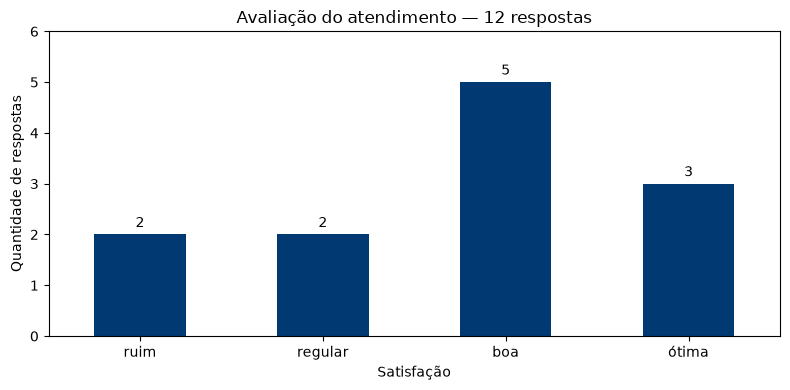

In [ ]:
# ■■■ 3. Visualização das contagens por categoria

ax = FQ_dataframe.plot.bar(
    x='resposta',
    y='absoluta',
    color='#013A72',
    figsize=(8, 4),
    rot=0,
    legend=False
)

# ====== Título, eixos e rótulos
ax.set_title(f'Avaliação do atendimento — {total} respostas')
ax.set_xlabel('Satisfação')
ax.set_ylabel('Quantidade de respostas')
ax.bar_label(ax.containers[0], padding=3)

# ====== Escala de contagens
maximo = int(FQ_dataframe['absoluta'].max())
ax.set_yticks(range(maximo + 2))
ax.set_ylim(0, maximo + 1)

plt.tight_layout()
plt.show()

In [19]:
# ■■■ 4. Proporção de avaliações boas ou ótimas

avaliacoes_positivas = FQ_dataframe.loc[
    FQ_dataframe['resposta'].isin(['boa', 'ótima']),
    'absoluta'
].sum()

proporcao_positiva = avaliacoes_positivas / total

# ====== Parágrafo para apresentar à equipe
print(
    f'Das {total} respostas recebidas, {avaliacoes_positivas} '
    f'classificaram o atendimento como bom ou ótimo, '
    f'representando {proporcao_positiva:.1%} das avaliações. '
    'Esse percentual descreve as pessoas que responderam à pesquisa.'
)

Das 12 respostas recebidas, 8 classificaram o atendimento como bom ou ótimo, representando 66.7% das avaliações. Esse percentual descreve as pessoas que responderam à pesquisa.


## Resultados e interpretação

Responda às perguntas do enunciado e explique os resultados.

## Conferência dos critérios

Registre as evidências de conclusão e as dúvidas que restaram.